# TF-IDF LinearSVC + 트리 모델 앙상블

트리 모델은 E8 파생변수의 구조적 특징을, TF-IDF + LinearSVC는 원본 변이 표기와 유전자-변이 조합의 희소 텍스트 패턴을 학습합니다. 서로 다른 표현의 정보를 결합해 단일 모델 대비 보완 효과가 있는지 확인합니다.

RandomForest와 LinearSVC, 두 모델의 고정 50:50 soft blend, 그리고 개발 데이터 OOF 예측으로 가중치/온도를 선택한 blend를 비교합니다. 그룹 분할로 동일 변이 프로필의 폴드 누출을 막고, 별도 holdout으로 최종 성능을 평가합니다. LinearSVC는 직접 확률을 내지 않으므로 decision score에 softmax를 적용한 뒤 blend하며, 이 값은 확률 보정된 추정치가 아니라 앙상블용 정규화 점수입니다. 최종에는 제출 파일도 생성합니다.

In [1]:
from pathlib import Path
import re
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.svm import LinearSVC

SEED = 42
cwd = Path.cwd()
project_root = next((p for p in (cwd, cwd.parent) if (p / "src" / "features.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("프로젝트 루트에서 src/features.py를 찾을 수 없습니다.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.features import build_features, gene_columns

train_all = pd.read_csv(project_root / "data" / "train.csv")
if "SUBCLASS" not in train_all.columns:
    raise KeyError("train.csv에 SUBCLASS 열이 없습니다.")
y_all = train_all["SUBCLASS"].astype("string").str.strip()
target_mask = y_all.notna() & y_all.ne("")
missing_target_count = int((~target_mask).sum())
train = train_all.loc[target_mask].reset_index(drop=True)
y = train["SUBCLASS"].astype(str)
genes = gene_columns(train)
if not genes:
    raise ValueError("학습 데이터에서 유전자 열을 찾을 수 없습니다.")
missing_gene_cells = int(train[genes].isna().sum().sum())
groups = pd.util.hash_pandas_object(train[genes].fillna("WT"), index=False).to_numpy()
class_labels = sorted(y.unique())
label_to_index = {label: i for i, label in enumerate(class_labels)}

print(f"학습 데이터: {len(train):,}행, {len(genes):,}개 유전자, {len(class_labels)}개 암종")
print(f"타깃 결측 제외: {missing_target_count:,}; 유전자 결측 셀: {missing_gene_cells:,}")
print(f"동일 변이 프로필 중복 행: {pd.Series(groups).duplicated().sum():,}")
display(y.value_counts().rename("sample_count").to_frame())

학습 데이터: 6,201행, 4,384개 유전자, 26개 암종
타깃 결측 제외: 0; 유전자 결측 셀: 0
동일 변이 프로필 중복 행: 565


,sample_count
SUBCLASS,
BRCA,786
KIPAN,515
GBMLGG,461
STES,379
KIRC,334
THCA,324
SKCM,276
PRAD,266
OV,253


### 데이터와 그룹 누출 점검

이 표는 타깃 클래스 분포를 확인하고, 타깃 결측 행과 유전자 결측 셀 및 동일 변이 프로필 중복을 요약합니다. 결측 유전자 셀은 기존 E8 빌더에서 WT로 채워 처리합니다. 모든 검증은 환자 단위 행이 아니라 완전히 동일한 프로필을 묶은 그룹 단위로 나눕니다.

In [2]:
def mutation_documents(frame, gene_cols):
    """Create one sparse-text document per row from gene and mutation tokens."""
    documents = []
    for row in frame[gene_cols].itertuples(index=False, name=None):
        terms = []
        for gene, value in zip(gene_cols, row):
            if not isinstance(value, str):
                continue
            value = value.strip()
            if not value or value.upper() in {"WT", "WILDTYPE", "WILD TYPE", "NORMAL", "NA", "N/A", "NAN", "NONE", "NULL"}:
                continue
            seen = set()
            for token in re.split(r"[\s,;|]+", value.upper()):
                token = token.strip()
                if not token or token in seen:
                    continue
                seen.add(token)
                mutation = re.sub(r"[^A-Z0-9*]+", "_", token).strip("_")
                if not mutation:
                    continue
                terms.extend((f"gene_{gene}", f"mut_{mutation}", f"event_{gene}_{mutation}"))
        documents.append(" ".join(terms) if terms else "no_mutation_token")
    return documents


def align_model_outputs(model, X, labels, output="proba"):
    if output == "proba":
        values = model.predict_proba(X)
    else:
        values = model.decision_function(X)
        if values.ndim == 1:
            values = np.column_stack([-values, values])
    # Sparse matrices do not define len(); use their row dimension explicitly.
    aligned = np.full((X.shape[0], len(labels)), -1e6 if output == "decision" else 0.0, dtype=np.float64)
    positions = {label: i for i, label in enumerate(labels)}
    for model_i, label in enumerate(model.classes_):
        aligned[:, positions[label]] = values[:, model_i]
    return aligned


def build_tree_model():
    return RandomForestClassifier(
        n_estimators=400,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1,
    )


def build_text_model():
    return LinearSVC(C=0.5, class_weight="balanced", random_state=SEED, max_iter=5000)

print("문서 생성 규칙 준비 완료: 유전자 토큰 + 변이 토큰 + gene-mutation 결합 토큰")

문서 생성 규칙 준비 완료: 유전자 토큰 + 변이 토큰 + gene-mutation 결합 토큰


### 두 가지 특성 표현

텍스트 문서는 각 환자에서 관찰된 유전자, 변이 표기, 그리고 유전자-변이 결합 토큰으로 구성됩니다. 중복 표기는 환자/유전자 내에서 한 번만 넣습니다. TF-IDF vocabulary는 매 CV fold의 학습 문서에서만 적합해 검증 정보를 미리 보지 않게 합니다. 트리 모델에는 동일 fold 학습분에서 만든 E8 파생변수만 전달합니다.

In [3]:
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, holdout_idx = next(outer_cv.split(train, y, groups))
dev = train.iloc[dev_idx].reset_index(drop=True)
holdout = train.iloc[holdout_idx].reset_index(drop=True)
y_dev = y.iloc[dev_idx].reset_index(drop=True)
y_holdout = y.iloc[holdout_idx].reset_index(drop=True)
groups_dev = groups[dev_idx]

n_classes = len(class_labels)
oof_rf = np.zeros((len(dev), n_classes), dtype=np.float32)
oof_svc_scores = np.full((len(dev), n_classes), -1e6, dtype=np.float32)
fold_rows = []
inner_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)

for fold, (fit_idx, valid_idx) in enumerate(inner_cv.split(dev, y_dev, groups_dev), start=1):
    fold_train = dev.iloc[fit_idx].reset_index(drop=True)
    fold_valid = dev.iloc[valid_idx].reset_index(drop=True)
    y_fold_train = y_dev.iloc[fit_idx]
    y_fold_valid = y_dev.iloc[valid_idx]

    X_tree_train, X_tree_valid = build_features(fold_train, fold_valid, level="E8")
    if list(X_tree_train.columns) != list(X_tree_valid.columns):
        raise ValueError(f"Fold {fold}: tree feature columns do not match.")

    docs_train = mutation_documents(fold_train, genes)
    docs_valid = mutation_documents(fold_valid, genes)
    vectorizer = TfidfVectorizer(
        lowercase=True,
        token_pattern=r"(?u)\b[\w*]+\b",
        min_df=2,
        max_features=250000,
        sublinear_tf=True,
        norm="l2",
        dtype=np.float32,
    )
    X_text_train = vectorizer.fit_transform(docs_train)
    X_text_valid = vectorizer.transform(docs_valid)

    tree_model = build_tree_model()
    tree_model.fit(X_tree_train, y_fold_train)
    text_model = build_text_model()
    text_model.fit(X_text_train, y_fold_train)

    fold_rf = align_model_outputs(tree_model, X_tree_valid, class_labels, output="proba")
    fold_svc = align_model_outputs(text_model, X_text_valid, class_labels, output="decision")
    oof_rf[valid_idx] = fold_rf
    oof_svc_scores[valid_idx] = fold_svc

    pred_rf = np.asarray(class_labels)[fold_rf.argmax(axis=1)]
    pred_svc = np.asarray(class_labels)[fold_svc.argmax(axis=1)]
    pred_blend = np.asarray(class_labels)[(0.5 * fold_rf + 0.5 * softmax(fold_svc, axis=1)).argmax(axis=1)]
    fold_rows.append({
        "fold": fold,
        "RandomForest Macro F1": f1_score(y_fold_valid, pred_rf, labels=class_labels, average="macro", zero_division=0),
        "LinearSVC Macro F1": f1_score(y_fold_valid, pred_svc, labels=class_labels, average="macro", zero_division=0),
        "Fixed blend Macro F1": f1_score(y_fold_valid, pred_blend, labels=class_labels, average="macro", zero_division=0),
        "TF-IDF terms": X_text_train.shape[1],
    })
    print(f"Fold {fold}/4 done — train text features: {X_text_train.shape[1]:,}")

fold_table = pd.DataFrame(fold_rows)
svc_oof_fixed = softmax(oof_svc_scores.astype(np.float64), axis=1)
rf_oof = oof_rf.astype(np.float64)
oof_model_predictions = {
    "RandomForest": np.asarray(class_labels)[rf_oof.argmax(axis=1)],
    "LinearSVC TF-IDF": np.asarray(class_labels)[oof_svc_scores.argmax(axis=1)],
    "Fixed blend (50:50)": np.asarray(class_labels)[(0.5 * rf_oof + 0.5 * svc_oof_fixed).argmax(axis=1)],
}
cv_columns = {
    "RandomForest": "RandomForest Macro F1",
    "LinearSVC TF-IDF": "LinearSVC Macro F1",
    "Fixed blend (50:50)": "Fixed blend Macro F1",
}
cv_summary = pd.DataFrame([
    {
        "Model": name,
        "OOF Macro F1": f1_score(y_dev, pred, labels=class_labels, average="macro", zero_division=0),
        "Fold Macro F1 mean": fold_table[cv_columns[name]].mean(),
        "Fold Macro F1 std": fold_table[cv_columns[name]].std(ddof=1),
    }
    for name, pred in oof_model_predictions.items()
])
display(fold_table.round(4))
display(cv_summary.sort_values("OOF Macro F1", ascending=False).round(4))

Fold 1/4 done — train text features: 41,889
Fold 2/4 done — train text features: 40,719
Fold 3/4 done — train text features: 44,405
Fold 4/4 done — train text features: 40,757


,fold,RandomForest Macro F1,LinearSVC Macro F1,Fixed blend Macro F1,TF-IDF terms
0,1,0.3835,0.3717,0.4083,41889
1,2,0.4014,0.3639,0.4287,40719
2,3,0.3938,0.3583,0.4082,44405
3,4,0.4043,0.3790,0.4281,40757


,Model,OOF Macro F1,Fold Macro F1 mean,Fold Macro F1 std
2,Fixed blend (50:50),0.4188,0.4183,0.0116
0,RandomForest,0.3971,0.3957,0.0093
1,LinearSVC TF-IDF,0.3695,0.3682,0.0091


### 그룹 CV 결과

각 fold에서 RF, LinearSVC, 고정 50:50 blend를 같은 검증 프로필에서 평가합니다. TF-IDF vocabulary와 E8 변환은 fold 학습분에만 적합됩니다. OOF 예측 점수와 fold별 Macro F1 평균/표준편차를 비교해 텍스트 모델이 트리와 다른 오류 신호를 제공하는지 살펴봅니다. 텍스트 변환을 위한 softmax는 SVC decision score의 정규화이며, calibrated probability로 해석하지 않습니다.

In [4]:
# Select blend weight and SVC score temperature using development OOF only.
blend_candidates = []
for temperature in (0.5, 1.0, 2.0, 4.0):
    svc_probs = softmax(oof_svc_scores.astype(np.float64) / temperature, axis=1)
    for rf_weight in (0.2, 0.35, 0.5, 0.65, 0.8):
        blended = rf_weight * rf_oof + (1.0 - rf_weight) * svc_probs
        prediction = np.asarray(class_labels)[blended.argmax(axis=1)]
        blend_candidates.append({
            "rf_weight": rf_weight,
            "svc_weight": 1.0 - rf_weight,
            "svc_temperature": temperature,
            "OOF Macro F1": f1_score(y_dev, prediction, labels=class_labels, average="macro", zero_division=0),
        })
blend_search_table = pd.DataFrame(blend_candidates).sort_values("OOF Macro F1", ascending=False).reset_index(drop=True)
best_blend = blend_search_table.iloc[0].to_dict()

# Compute the selected blend's OOF metrics. Its OOF score is selection-biased; holdout remains untouched.
tuned_svc_oof_probs = softmax(oof_svc_scores.astype(np.float64) / best_blend["svc_temperature"], axis=1)
tuned_oof_scores = best_blend["rf_weight"] * rf_oof + best_blend["svc_weight"] * tuned_svc_oof_probs
tuned_oof_prediction = np.asarray(class_labels)[tuned_oof_scores.argmax(axis=1)]
tuned_blend_oof_f1 = f1_score(y_dev, tuned_oof_prediction, labels=class_labels, average="macro", zero_division=0)
tuned_blend_fold_scores = []
for _, fold_valid_idx in inner_cv.split(dev, y_dev, groups_dev):
    fold_prediction = np.asarray(class_labels)[tuned_oof_scores[fold_valid_idx].argmax(axis=1)]
    tuned_blend_fold_scores.append(f1_score(
        y_dev.iloc[fold_valid_idx], fold_prediction,
        labels=class_labels, average="macro", zero_division=0,
    ))

# Train each modality on development data and evaluate the frozen blend on untouched groups.
X_tree_dev, X_tree_holdout = build_features(dev, holdout, level="E8")
if list(X_tree_dev.columns) != list(X_tree_holdout.columns):
    raise ValueError("개발/홀드아웃 트리 특성 열이 일치하지 않습니다.")
vectorizer_holdout = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b[\w*]+\b",
    min_df=2,
    max_features=250000,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32,
)
docs_dev = mutation_documents(dev, genes)
docs_holdout = mutation_documents(holdout, genes)
X_text_dev = vectorizer_holdout.fit_transform(docs_dev)
X_text_holdout = vectorizer_holdout.transform(docs_holdout)

rf_holdout_model = build_tree_model()
started = time.perf_counter()
rf_holdout_model.fit(X_tree_dev, y_dev)
rf_fit_seconds = time.perf_counter() - started
svc_holdout_model = build_text_model()
started = time.perf_counter()
svc_holdout_model.fit(X_text_dev, y_dev)
svc_fit_seconds = time.perf_counter() - started

rf_holdout_scores = align_model_outputs(rf_holdout_model, X_tree_holdout, class_labels, output="proba")
svc_holdout_scores = align_model_outputs(svc_holdout_model, X_text_holdout, class_labels, output="decision")
fixed_svc_holdout_probs = softmax(svc_holdout_scores, axis=1)
tuned_svc_holdout_probs = softmax(svc_holdout_scores / best_blend["svc_temperature"], axis=1)
fixed_blend_holdout_scores = 0.5 * rf_holdout_scores + 0.5 * fixed_svc_holdout_probs
tuned_blend_holdout_scores = best_blend["rf_weight"] * rf_holdout_scores + best_blend["svc_weight"] * tuned_svc_holdout_probs

holdout_predictions = {
    "RandomForest": np.asarray(class_labels)[rf_holdout_scores.argmax(axis=1)],
    "LinearSVC TF-IDF": np.asarray(class_labels)[svc_holdout_scores.argmax(axis=1)],
    "Fixed blend (50:50)": np.asarray(class_labels)[fixed_blend_holdout_scores.argmax(axis=1)],
    "OOF-tuned blend": np.asarray(class_labels)[tuned_blend_holdout_scores.argmax(axis=1)],
}
fit_times = {
    "RandomForest": rf_fit_seconds,
    "LinearSVC TF-IDF": svc_fit_seconds,
    "Fixed blend (50:50)": rf_fit_seconds + svc_fit_seconds,
    "OOF-tuned blend": rf_fit_seconds + svc_fit_seconds,
}
comparison_rows = []
for name, prediction in holdout_predictions.items():
    if name == "OOF-tuned blend":
        oof_f1 = tuned_blend_oof_f1
        oof_mean = float(np.mean(tuned_blend_fold_scores))
        oof_std = float(np.std(tuned_blend_fold_scores, ddof=1))
    else:
        matching_cv = cv_summary.loc[cv_summary["Model"].eq(name)].iloc[0]
        oof_f1 = matching_cv["OOF Macro F1"]
        oof_mean = matching_cv["Fold Macro F1 mean"]
        oof_std = matching_cv["Fold Macro F1 std"]
    comparison_rows.append({
        "Model": name,
        "OOF Macro F1": oof_f1,
        "OOF fold mean": oof_mean,
        "OOF fold std": oof_std,
        "Holdout Macro F1": f1_score(y_holdout, prediction, labels=class_labels, average="macro", zero_division=0),
        "Holdout Balanced Accuracy": balanced_accuracy_score(y_holdout, prediction),
        "Holdout Weighted F1": f1_score(y_holdout, prediction, labels=class_labels, average="weighted", zero_division=0),
        "Holdout Accuracy": accuracy_score(y_holdout, prediction),
        "Fit seconds": fit_times[name],
    })
comparison_table = pd.DataFrame(comparison_rows).sort_values("OOF Macro F1", ascending=False).reset_index(drop=True)
print("Blend weights selected on development OOF only:", {k: round(v, 4) if isinstance(v, float) else v for k, v in best_blend.items()})
display(blend_search_table.head(8).round(4))
display(comparison_table.round(4))

# Use the OOF-selected blend for final refit, not the holdout-selected model.
selected_model_name = "OOF-tuned blend"
best_holdout_prediction = holdout_predictions[selected_model_name]
print(f"Final candidate: {selected_model_name}; untouched holdout Macro F1: {comparison_table.loc[comparison_table['Model'].eq(selected_model_name), 'Holdout Macro F1'].iloc[0]:.4f}")

Blend weights selected on development OOF only: {'rf_weight': 0.2, 'svc_weight': 0.8, 'svc_temperature': 1.0, 'OOF Macro F1': 0.4477}


,rf_weight,svc_weight,svc_temperature,OOF Macro F1
0,0.20,0.80,1.0,0.4477
1,0.35,0.65,0.5,0.4444
2,0.20,0.80,0.5,0.4423
3,0.50,0.50,0.5,0.4373
4,0.35,0.65,1.0,0.4307
5,0.20,0.80,2.0,0.4287
6,0.65,0.35,0.5,0.4271
7,0.50,0.50,1.0,0.4188


,Model,OOF Macro F1,OOF fold mean,OOF fold std,Holdout Macro F1,Holdout Balanced Accuracy,Holdout Weighted F1,Holdout Accuracy,Fit seconds
0,OOF-tuned blend,0.4477,0.4469,0.0105,0.4551,0.4944,0.4460,0.4569,1.9110
1,Fixed blend (50:50),0.4188,0.4183,0.0116,0.4374,0.4773,0.4277,0.4384,1.9110
2,RandomForest,0.3971,0.3957,0.0093,0.4162,0.4559,0.4111,0.4239,1.6405
3,LinearSVC TF-IDF,0.3695,0.3682,0.0091,0.3510,0.3719,0.3485,0.3537,0.2706


Final candidate: OOF-tuned blend; untouched holdout Macro F1: 0.4551


### 앙상블 가중치 선택과 홀드아웃 표

개발 OOF 예측에서만 RF 비중(0.20~0.80)과 SVC decision score의 softmax 온도를 탐색합니다. 이 과정은 OOF 점수에 선택 편향을 만들 수 있으므로, 튜닝 OOF 수치만 보고 개선을 주장하지 않고 별도 grouped holdout 결과를 함께 봅니다. 최종 비교표에는 RF, 텍스트 LinearSVC, 고정 50:50, OOF에서 선택한 blend의 OOF와 holdout 지표를 함께 표시합니다. SVC softmax는 확률 보정된 추정치가 아니므로, 가중치 역시 검증을 통해 결정한 앙상블 설정으로만 해석합니다.

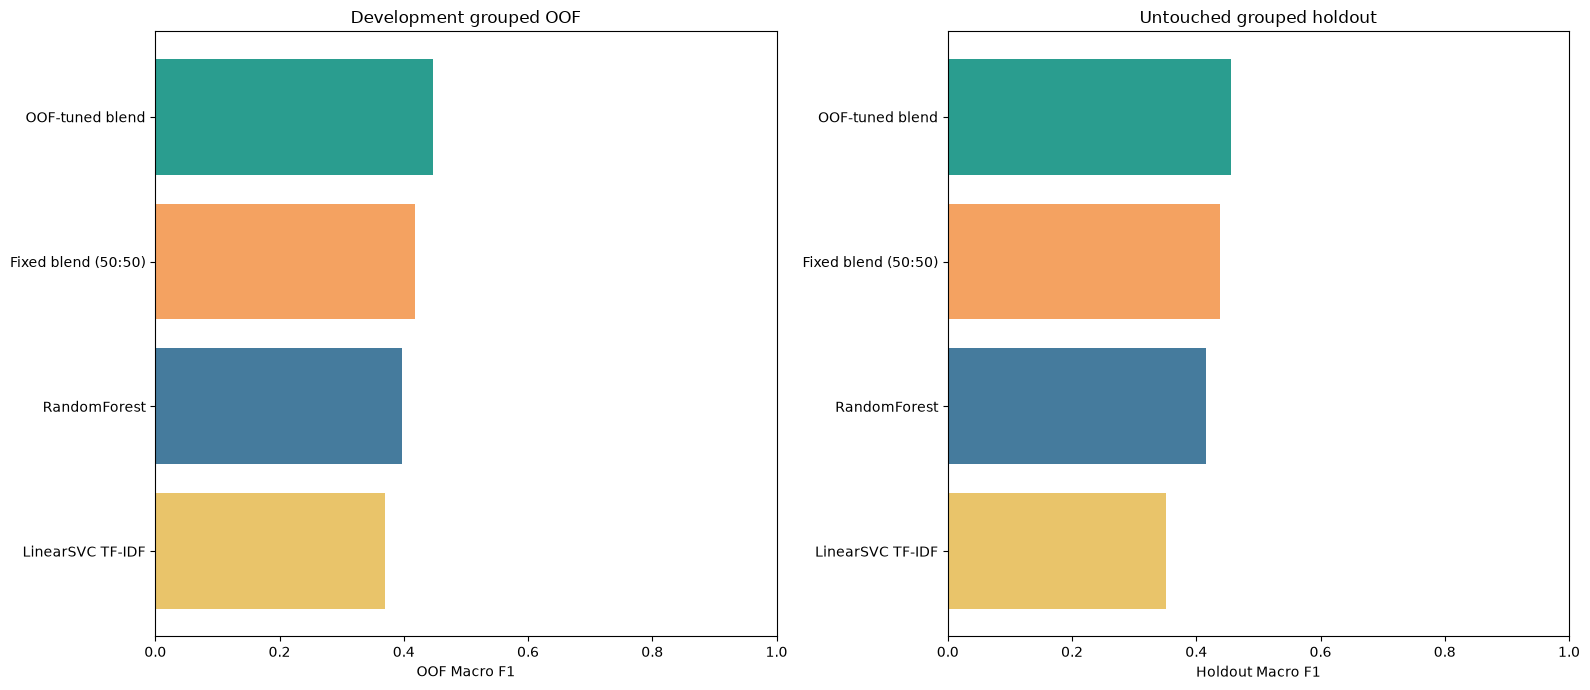

,holdout_f1
LUAD,0.122449
SARC,0.190476
GBMLGG,0.224138
HNSC,0.293333
PAAD,0.304348
CESC,0.328767
PCPG,0.333333
KIPAN,0.339181
BLCA,0.342857
PRAD,0.357143


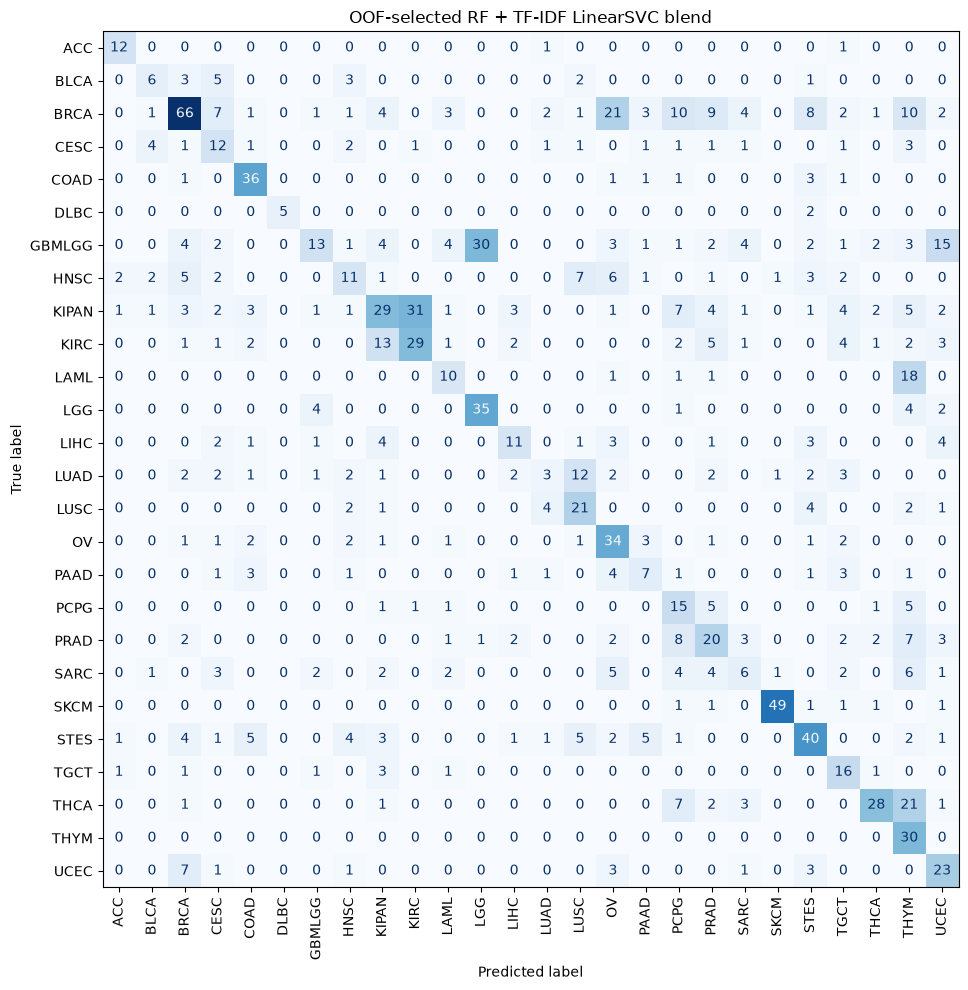

In [5]:
colors = {
    "RandomForest": "#457b9d",
    "LinearSVC TF-IDF": "#e9c46a",
    "Fixed blend (50:50)": "#f4a261",
    "OOF-tuned blend": "#2a9d8f",
}
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, metric, title in [
    (axes[0], "OOF Macro F1", "Development grouped OOF"),
    (axes[1], "Holdout Macro F1", "Untouched grouped holdout"),
]:
    ordered = comparison_table.sort_values(metric, ascending=True)
    ax.barh(ordered["Model"], ordered[metric], color=[colors[name] for name in ordered["Model"]])
    ax.set_xlim(0, 1)
    ax.set_xlabel(metric)
    ax.set_title(title)
fig.tight_layout()
plt.show()

selected_holdout_report = classification_report(
    y_holdout,
    best_holdout_prediction,
    labels=class_labels,
    output_dict=True,
    zero_division=0,
)
class_f1 = pd.Series({label: selected_holdout_report[label]["f1-score"] for label in class_labels}, name="holdout_f1").sort_values()
display(class_f1.to_frame())
fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay.from_predictions(
    y_holdout,
    best_holdout_prediction,
    labels=class_labels,
    display_labels=class_labels,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("OOF-selected RF + TF-IDF LinearSVC blend")
fig.tight_layout()
plt.show()

### 홀드아웃 점수와 클래스별 혼동

그래프는 CV OOF와 미사용 holdout의 Macro F1을 나란히 보여주며, 클래스별 표와 혼동행렬은 OOF 선택 blend의 오류 양상을 요약합니다. 특정 암종에서 낮은 F1이 보이면 전체 Macro F1만으로 개선을 판단하지 말고 그 암종의 오분류 상대를 확인합니다. holdout 성능이 OOF 결과와 크게 다르면 모델/가중치 선택의 불확실성이 큰 것으로 해석합니다.

In [6]:
test = pd.read_csv(project_root / "data" / "test.csv")
X_tree_train_final, X_tree_test = build_features(train, test, level="E8")
if list(X_tree_train_final.columns) != list(X_tree_test.columns):
    raise ValueError("전체 학습/테스트 E8 특성 열이 일치하지 않습니다.")

final_vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b[\w*]+\b",
    min_df=2,
    max_features=250000,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32,
)
X_text_train_final = final_vectorizer.fit_transform(mutation_documents(train, genes))
X_text_test = final_vectorizer.transform(mutation_documents(test, genes))

final_rf = build_tree_model()
final_rf.fit(X_tree_train_final, y)
final_svc = build_text_model()
final_svc.fit(X_text_train_final, y)
rf_test_scores = align_model_outputs(final_rf, X_tree_test, class_labels, output="proba")
svc_test_scores = align_model_outputs(final_svc, X_text_test, class_labels, output="decision")
svc_test_probs = softmax(svc_test_scores / best_blend["svc_temperature"], axis=1)
ensemble_test_scores = best_blend["rf_weight"] * rf_test_scores + best_blend["svc_weight"] * svc_test_probs
test_predictions = np.asarray(class_labels)[ensemble_test_scores.argmax(axis=1)]

submission = pd.read_csv(project_root / "data" / "sample_submission.csv")
if "ID" in submission.columns and "ID" in test.columns:
    if test["ID"].duplicated().any():
        raise ValueError("test.csv의 ID가 중복되어 제출 행에 안전하게 매핑할 수 없습니다.")
    prediction_by_id = pd.Series(test_predictions, index=test["ID"])
    submission["SUBCLASS"] = submission["ID"].map(prediction_by_id)
    if submission["SUBCLASS"].isna().any():
        raise ValueError("sample_submission.csv의 일부 ID에 대한 예측을 찾지 못했습니다.")
elif len(submission) == len(test_predictions):
    submission["SUBCLASS"] = test_predictions
else:
    raise ValueError("sample_submission.csv와 test.csv의 행 수 또는 ID 열을 확인하세요.")

output_path = project_root / "submissions" / "1109_myeongseok_rf_tfidf_linearsvc_ensemble.csv"
submission.to_csv(output_path, index=False, encoding="utf-8-sig")
print(f"최종 blend: RF {best_blend['rf_weight']:.2f} + LinearSVC {best_blend['svc_weight']:.2f}")
print(f"SVC softmax temperature: {best_blend['svc_temperature']:.2f}")
print(f"개발 OOF Macro F1 (weight selection score): {best_blend['OOF Macro F1']:.4f}")
print(f"미사용 grouped holdout Macro F1: {comparison_table.loc[comparison_table['Model'].eq('OOF-tuned blend'), 'Holdout Macro F1'].iloc[0]:.4f}")
print(f"제출 파일 저장: {output_path}")

최종 blend: RF 0.20 + LinearSVC 0.80
SVC softmax temperature: 1.00
개발 OOF Macro F1 (weight selection score): 0.4477
미사용 grouped holdout Macro F1: 0.4551
제출 파일 저장: c:\AI수업\데이콘과제\암종 분류\submissions\1109_myeongseok_rf_tfidf_linearsvc_ensemble.csv


### 제출 파일 생성

최종 모델은 전체 라벨 있는 학습 데이터로 RF와 TF-IDF LinearSVC를 각각 다시 학습하고, 개발 OOF에서 선택한 블렌딩 가중치와 SVC 온도로 test 예측을 생성합니다. 예측은 `sample_submission.csv`의 ID 순서에 맞춰 저장합니다. 여기에 출력된 홀드아웃 점수는 로컬 검증값이며, 실제 대회 성능은 제출 후 리더보드에서 확인해야 합니다.

### Q&A
- 왜 RF와 TF-IDF LinearSVC를 결합하나요? RF는 E8 구조적 파생변수를, LinearSVC는 원본 변이 문자열의 희소 텍스트 패턴을 학습해 서로 다른 입력 표현의 정보를 결합합니다.
- 앙상블이 개선되었나요? 실행 후 OOF와 미사용 grouped holdout 결과표를 확인해야 합니다. SVC 점수를 softmax로 바꾸는 것은 확률 보정이 아니며, 앙상블 효과는 홀드아웃 점수로 검증합니다.

### Data Analysis Key Findings
- 비교 대상은 RandomForest, TF-IDF LinearSVC, 고정 50:50 blend, OOF에서 선택한 blend입니다. 각 모델의 grouped OOF와 holdout Macro F1, 보조 지표, fold 편차와 학습 시간을 표에 제공합니다.
- 모델 결과는 노트북 실행 전에는 알 수 없으므로 특정 후보가 더 우수하다고 미리 단정하지 않습니다. 최종 blend는 개발 OOF에서 선택한 가중치로 학습하며, 별도 holdout으로 선택 결과를 점검합니다.

### Insights or Next Steps
- 셀을 순서대로 실행해 점수표를 확인하고, 앙상블이 단일 모델보다 holdout에서 이득이 있는지 검토하세요.
- 실행된 최종 셀은 가중치 설정으로 제출 파일을 생성합니다. 리더보드 점수를 기록해 실제 일반화 성능과 비교하세요.